# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Ilham Fajar Setiawan
- NIM   : 241011402452
- Kelas : **Reg B**

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM 241011402452 -> 52
RANDOM_STATE = 52

print('RANDOM_STATE =', RANDOM_STATE)

RANDOM_STATE = 52


In [2]:
# Salin fungsi train_test_split dari materi (simple_regression/regression_1.ipynb & simple_classification/classification_1.ipynb)
# fungsi ini membagi dataset menjadi data training dan testing berdasarkan test_size dan random_state.
# contoh:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

In [3]:
# Salin implementasi model dari materi:
# - LinearRegression (normal equation) & LinearRegressionGD -> materi simple_regression/regression_1.ipynb
# - LogisticRegression (gradient descent)                    -> materi simple_classification/classification_1.ipynb

class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    # Training
    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    # Testing
    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [4]:
# Metrik evaluasi yang dipakai lintas soal (accuracy & confusion_matrix dari materi classification)
# accuracy: proporsi prediksi yang benar
# confusion_matrix: [[TN, FP],
#                    [FN, TP]]

def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp],
                     [fn, tp]])

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


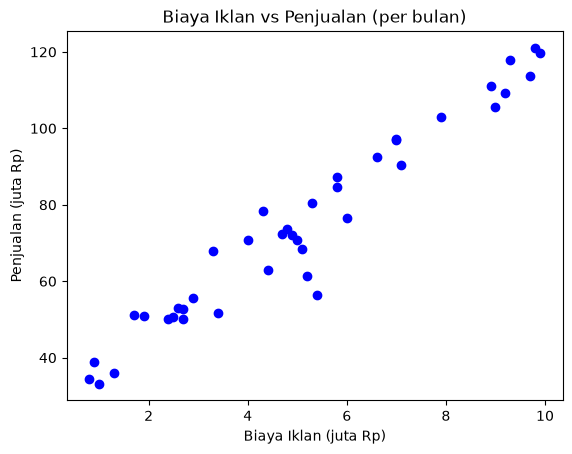

In [5]:
# Jawaban A1
# 1. Baca dataset & tampilkan 5 data pertama + jumlah baris
ads_data = pd.read_csv('Ads_Data.csv')
display(ads_data.head())
print('Jumlah baris data:', len(ads_data))

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X 2 dimensi (n, 1)
X = ads_data.iloc[:, 0].values      # kolom BiayaIklan (1 dimensi)
X = X.reshape(-1, 1)                 # ubah ke 2 dimensi (n, 1)
y = ads_data.iloc[:, 1].values       # kolom Penjualan

print('Shape X:', X.shape)
print('Shape y:', y.shape)

# 3. Scatter plot BiayaIklan vs Penjualan
plt.scatter(X, y, c='blue')
plt.title('Biaya Iklan vs Penjualan (per bulan)')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
# Split data: 80% training, 20% testing, random_state = 52 (2 digit terakhir NIM)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

Intercept (b) : 29.437522627969653
Koefisien (m) : 9.009130791138693

Persamaan garis regresi: y_hat = 29.4375 + 9.0091 * X


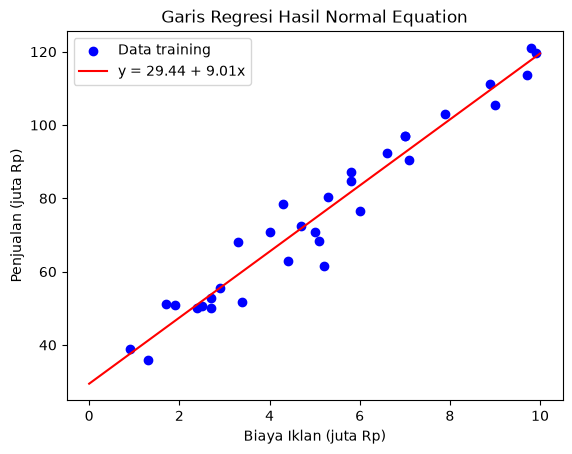

In [7]:
# Jawaban A3
# 1. Training dengan normal equation (implementasi dari materi)
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# 2. Tampilkan intercept (b) dan koefisien (m), lalu tulis persamaannya
b = regressor.intercept_
m = regressor.coefficients_[0]
print('Intercept (b) :', b)
print('Koefisien (m) :', m)
print()
print(f'Persamaan garis regresi: y_hat = {b:.4f} + {m:.4f} * X')

# garis regresi di atas data training (untuk memperjelas persamaan)
plt.scatter(X_train, y_train, c='blue', label='Data training')
x_line = np.linspace(0, 10, 100)
plt.plot(x_line, b + m * x_line, c='r', label=f'y = {b:.2f} + {m:.2f}x')
plt.title('Garis Regresi Hasil Normal Equation')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.show()

**Jawaban A3 (interpretasi):**

Hasil training dengan normal equation: $b = 29,4375$ dan $m = 9,0091$, jadi persamaan garisnya:

$$\hat{y} = 29,44 + 9,01X$$

Arti nilai $m$: kalau biaya iklan naik 1 juta Rp per bulan, penjualan naik sekitar 9,01 juta Rp per bulan. Untuk intercept-nya, $b = 29,44$ artinya kalau toko tidak pasang iklan sama sekali ($X=0$), masih ada penjualan sekitar 29,44 juta Rp per bulan — mungkin dari pembeli yang datang sendiri tanpa iklan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4
# Implementasi metrik evaluasi regresi dengan NumPy (tanpa sklearn)
def mean_absolute_error(y_true, y_pred):
    # MAE = rata-rata dari nilai absolut selisih prediksi vs aktual
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

def mean_squared_error(y_true, y_pred):
    # MSE = rata-rata dari kuadrat selisih prediksi vs aktual
    return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

def root_mean_squared_error(y_true, y_pred):
    # RMSE = akar kuadrat dari MSE (satuan sama dengan data asli)
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    # R^2 = 1 - SS_res / SS_tot : proporsi variasi data yang berhasil dijelaskan model
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

# 1. Hitung MAE, MSE, RMSE, R^2 pada data training dan testing
hasil = {}
for nama, y_aktual, y_prediksi in [('training', y_train, regressor.predict(X_train)),
                                    ('testing',  y_test,  regressor.predict(X_test))]:
    hasil[nama] = [mean_absolute_error(y_aktual, y_prediksi),
                   mean_squared_error(y_aktual, y_prediksi),
                   root_mean_squared_error(y_aktual, y_prediksi),
                   r2_score(y_aktual, y_prediksi)]

# 2. Tampilkan hasilnya dalam satu tabel
tabel_eval = pd.DataFrame(hasil, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)
tabel_eval

,training,testing
MAE,4.3895,4.9646
MSE,28.9508,67.2248
RMSE,5.3806,8.1991
R2,0.9489,0.9224


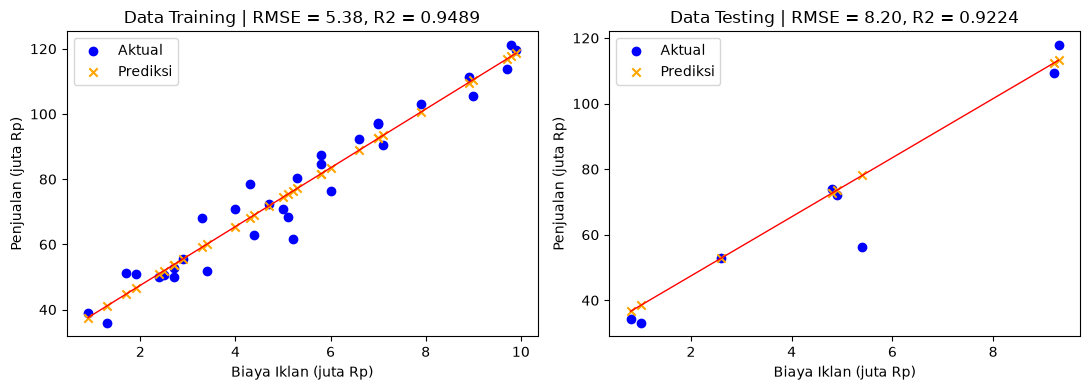

In [9]:
# Visualisasi tambahan: prediksi vs aktual di kedua data
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, nama, X_d, y_d in [(axes[0], 'Training', X_train, y_train),
                           (axes[1], 'Testing', X_test, y_test)]:
    y_p = regressor.predict(X_d)
    ax.scatter(X_d, y_d, c='blue', label='Aktual')
    ax.scatter(X_d, y_p, c='orange', marker='x', label='Prediksi')
    ax.plot(np.sort(X_d, axis=0).ravel(), regressor.predict(np.sort(X_d, axis=0)), c='r', lw=1)
    ax.set_title(f'Data {nama} | RMSE = {root_mean_squared_error(y_d, y_p):.2f}, R2 = {r2_score(y_d, y_p):.4f}')
    ax.set_xlabel('Biaya Iklan (juta Rp)')
    ax.set_ylabel('Penjualan (juta Rp)')
    ax.legend()

plt.tight_layout()
plt.show()

**Jawaban A4 (analisis):**

| Metrik | Training | Testing |
|---|---|---|
| MAE | 4,3895 | 4,9646 |
| MSE | 28,9508 | 67,2248 |
| RMSE | 5,3806 | 8,1991 |
| $R^2$ | 0,9489 | 0,9224 |

RMSE testing 8,20 berarti rata-rata prediksi penjualan meleset sekitar 8,2 juta Rp dari penjualan sebenarnya. RMSE-nya jauh lebih besar dari MAE (4,96) karena RMSE menguadratkan selisihnya, jadi model ini kena "hukuman" dari beberapa titik testing yang meleset jauh.

$R^2$ testing 0,9224 artinya sekitar 92% naik-turunnya penjualan bisa dijelaskan oleh biaya iklan, sisanya (8%) dipengaruhi faktor lain yang tidak ada di model, misalnya musim atau harga kompetitor.

Apakah modelnya sudah baik? Setahuku ini sudah tergolong baik. $R^2$ training dan testing sama-sama tinggi dan selisihnya kecil (0,949 vs 0,922), jadi tidak ada tanda overfitting. RMSE 8,2 juta juga masih wajar kalau dibanding rentang penjualan di data yang 33 sampai 121 juta.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

learning_rate = 0.001
  intercept   : 19.18406314162219
  koefisien   : [10.61523754]
  loss awal   : 5886.1355
  loss akhir  : 50.088213
  dibanding normal equation: b = 29.4375, m = 9.0091



learning_rate = 0.02
  intercept   : 29.43752254894955
  koefisien   : [9.0091308]
  loss awal   : 823.2101
  loss akhir  : 28.950766
  dibanding normal equation: b = 29.4375, m = 9.0091



learning_rate = 0.1
  intercept   : nan
  koefisien   : [nan]
  loss awal   : 34675.6343
  loss akhir  : nan
  dibanding normal equation: b = 29.4375, m = 9.0091



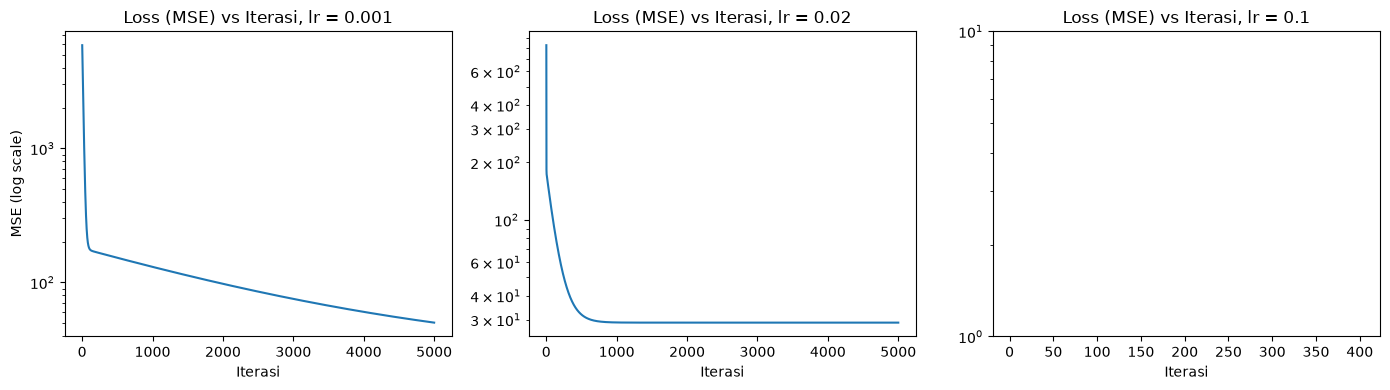

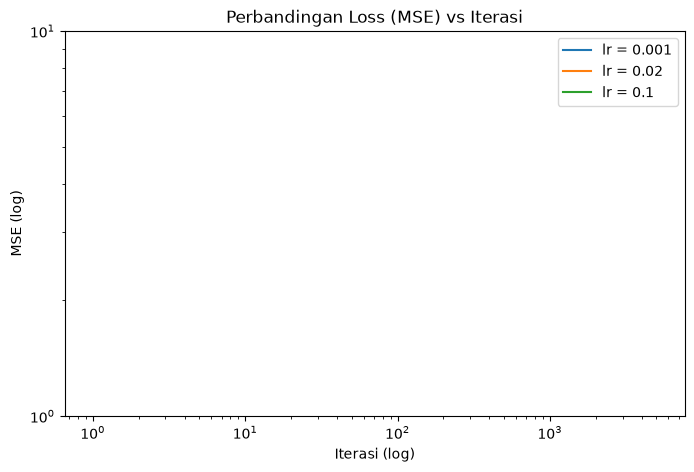

In [10]:
# Jawaban A5
# 1-3. Latih LinearRegressionGD dengan 3 learning rate, tampilkan hasil + grafik loss
learning_rates = [0.001, 0.02, 0.1]
model_gd = {}

np.seterr(all='ignore')   # biar RuntimeWarning overflow tidak memutus output; ini bagian dari eksperimen (dijelaskan di A5)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, lr in zip(axes, learning_rates):
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    model_gd[lr] = gd

    loss = np.array(gd.loss_history_)
    print(f'learning_rate = {lr}')
    print(f'  intercept   : {gd.intercept_}')
    print(f'  koefisien   : {gd.coefficients_}')
    print(f'  loss awal   : {loss[0]:.4f}')
    print(f'  loss akhir  : {loss[-1]:.6f}')
    print(f'  dibanding normal equation: b = {regressor.intercept_:.4f}, m = {regressor.coefficients_[0]:.4f}')
    print()

    ax.plot(range(1, len(loss) + 1), loss)
    ax.set_yscale('log')
    ax.set_title(f'Loss (MSE) vs Iterasi, lr = {lr}')
    ax.set_xlabel('Iterasi')
    if lr == learning_rates[0]:
        ax.set_ylabel('MSE (log scale)')

plt.tight_layout()
plt.show()

# bandingkan konvergensi ketiganya dalam satu grafik (skala log)
plt.figure(figsize=(8, 5))
for lr in learning_rates:
    loss = np.array(model_gd[lr].loss_history_, dtype=float)
    plt.plot(range(1, len(loss) + 1), loss, label=f'lr = {lr}')
plt.xscale('log'); plt.yscale('log')
plt.title('Perbandingan Loss (MSE) vs Iterasi')
plt.xlabel('Iterasi (log)')
plt.ylabel('MSE (log)')
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

Hasil ketiga learning rate (5000 iterasi), dibandingkan normal equation sebagai pembanding:

| Learning rate | Intercept | Koefisien | Loss akhir | Keterangan |
|---|---|---|---|---|
| Normal equation | 29,4375 | 9,0091 | 28,9508 | pembanding (optimum) |
| 0.001 | 19,1841 | 10,6152 | 50,0882 | konvergen tapi terlalu lambat |
| 0.02 | 29,4375 | 9,0091 | 28,9508 | pas, hasilnya sama dengan normal equation |
| 0.1 | NaN | NaN | overflow lalu NaN | gagal konvergen (divergen) |

- lr = 0.001 terlalu lambat: setelah 5000 iterasi loss-nya masih 50,09, jauh dari 28,95, dan koefisiennya ($b=19,18$, $m=10,62$) masih jauh dari normal equation. Langkahnya terlalu kecil jadi gerakannya lambat banget. Kalau iterasinya ditambah pasti sampai, tapi butuh waktu lama.
- lr = 0.02 pas: loss turun mulus dan hasil akhirnya sama persis dengan normal equation, jadi GD berhasil mencapai titik optimum.
- lr = 0.1 divergen: di grafik loss (skala log) kurvanya malah naik terus, muncul `RuntimeWarning: overflow` lalu loss jadi NaN di sekitar iterasi ke-403. Overflow ini memang bagian dari eksperimen, bukan bug kode.

Kenapa bisa begini? Pembaruan parameternya $\beta_{baru} = \beta - \alpha \nabla MSE$. Data ini punya kurva loss yang cukup curam (nilai $y$ sampai ratusan, gradientnya besar). Kalau $\alpha$ kelewat besar, satu langkah malah melompati dasar lembah dan mendarat di sisi lain yang lebih tinggi. Dari situ gradient berikutnya makin besar, langkah makin besar, terus berlipat sampai angkanya meluap (inf, lalu NaN). Jadi learning rate terlalu besar bukannya mempercepat, tapi bikin training gagal total.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

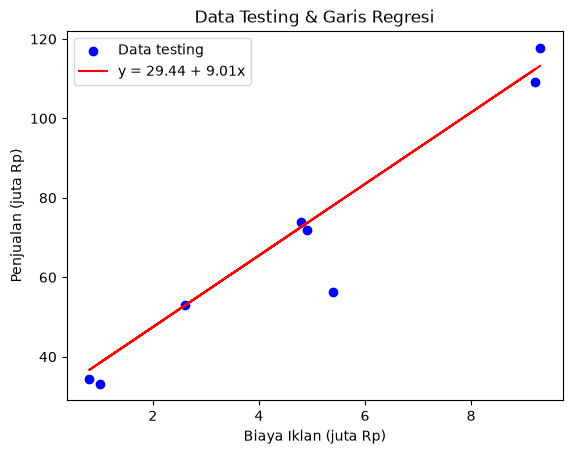

Biaya iklan  4.5 juta -> prediksi penjualan 69.98 juta
Biaya iklan  7.0 juta -> prediksi penjualan 92.50 juta
Biaya iklan 12.0 juta -> prediksi penjualan 137.55 juta

Catatan: rentang BiayaIklan pada data adalah 0.8 - 9.9 juta
-> prediksi 12 juta ada di LUAR rentang data (ekstrapolasi), analisis di markdown.


In [11]:
# Jawaban A6
# 1. Scatter data testing + garis regresi hasil model (normal equation)
plt.scatter(X_test, y_test, c='blue', label='Data testing')
plt.plot(X_test, regressor.predict(X_test), c='r',
         label=f'y = {regressor.intercept_:.2f} + {regressor.coefficients_[0]:.2f}x')
plt.title('Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5, 7, dan 12 juta
biaya_baru = [[4.5], [7.0], [12.0]]
prediksi_baru = regressor.predict(biaya_baru)
for x_baru, y_baru in zip(biaya_baru, prediksi_baru):
    print(f'Biaya iklan {x_baru[0]:>4} juta -> prediksi penjualan {y_baru:.2f} juta')

print()
print('Catatan: rentang BiayaIklan pada data adalah', ads_data['BiayaIklan'].min(), '-', ads_data['BiayaIklan'].max(), 'juta')
print('-> prediksi 12 juta ada di LUAR rentang data (ekstrapolasi), analisis di markdown.')

**Jawaban A6 (analisis):**

Garis regresi di grafik testing mengikuti sebaran data dengan cukup rapat. Hasil prediksinya:

| Biaya Iklan | Prediksi Penjualan |
|---|---|
| 4,5 juta | 69,98 juta |
| 7 juta | 92,50 juta |
| 12 juta | 137,55 juta |

Untuk prediksi 12 juta, saya tidak terlalu percaya. Rentang BiayaIklan di data cuma 0,8 sampai 9,9 juta, sedangkan 12 juta ada di luar itu (ekstrapolasi). Model cuma tahu pola di dalam rentang data yang dia lihat, di luar itu kita tidak ada jaminan hubungannya tetap linear. Di dunia nyata biasanya ada titik jenuh: setelah budget iklan tertentu, tambahan iklan tidak selalu menambah penjualan secara sama rata. Jadi 137,55 juta itu boleh dipakai sebagai perkiraan kasar "kalau polanya memang tetap linear", tapi jangan dipakai buat keputusan serius. Kalau 4,5 dan 7 juta masih masuk akal karena masih di dalam rentang data (interpolasi).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email:
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64

Shape X: (60, 2)
Shape y: (60,)


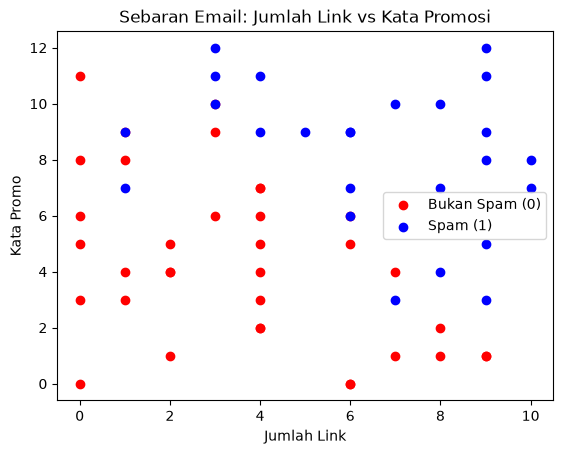

In [12]:
# Jawaban B1
# 1. Baca dataset, tampilkan 5 data pertama, hitung jumlah Spam vs Bukan Spam
email_data = pd.read_csv('Email_Data.csv')
display(email_data.head())
print('Jumlah email:')
print(email_data['Spam'].value_counts().rename(index={0: 'Bukan Spam (0)', 1: 'Spam (1)'}))

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X = email_data.iloc[:, :2].values     # 2 fitur: JumlahLink, KataPromo
y = email_data.iloc[:, 2].values      # label Spam

print()
print('Shape X:', X.shape)
print('Shape y:', y.shape)

# 3. Scatter plot dengan warna berbeda untuk Spam dan Bukan Spam
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', label='Bukan Spam (0)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', label='Spam (1)')
plt.title('Sebaran Email: Jumlah Link vs Kata Promosi')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2)
X_test : (15, 2)
y_train: (45,)
y_test : (15,)



Intercept (b)  : -11.047824933553748
Koefisien (m1) : 0.9466376178061984
Koefisien (m2) : 0.9278330919942875

P(Spam) = sigmoid(-11.0478 + 0.9466*JumlahLink + 0.9278*KataPromo)


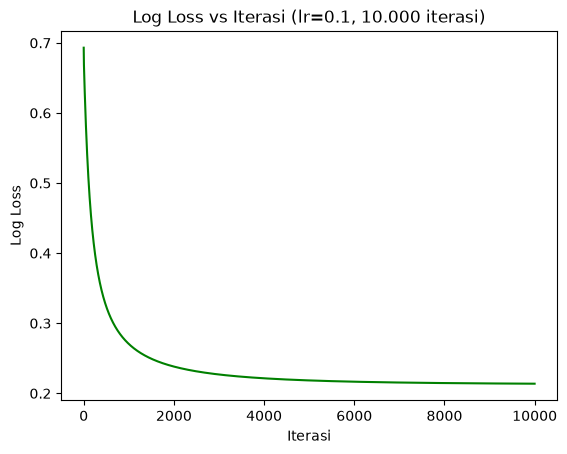

Loss awal  : 0.6931
Loss akhir : 0.213740


In [13]:
# Jawaban B2
# 1. Split data: 75% training, 25% testing, random_state = 52 (2 digit terakhir NIM)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

print('X_train:', X_train2.shape)
print('X_test :', X_test2.shape)
print('y_train:', y_train2.shape)
print('y_test :', y_test2.shape)

# 2. Latih LogisticRegression (gradient descent, dari materi)
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train2, y_train2)

# 3. Tampilkan intercept dan koefisien + persamaannya
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print()
print('Intercept (b)  :', b)
print('Koefisien (m1) :', m1)
print('Koefisien (m2) :', m2)
print()
print(f'P(Spam) = sigmoid({b:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)')

# 4. Grafik log loss vs iterasi
plt.plot(classifier.loss_history_, c='g')
plt.title('Log Loss vs Iterasi (lr=0.1, 10.000 iterasi)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.show()

print('Loss awal  : %.4f' % classifier.loss_history_[0])
print('Loss akhir : %.6f' % classifier.loss_history_[-1])

**Jawaban B2 (analisis):**

Hasil training: $b = -11,0478$, $m_1 = 0,9466$ (JumlahLink), $m_2 = 0,9278$ (KataPromo). Modelnya:

$$P(\text{Spam}) = \sigma(-11,05 + 0,947 \cdot \text{JumlahLink} + 0,928 \cdot \text{KataPromo})$$

Kedua koefisien positif, jadi makin banyak link atau kata promo, makin besar kemungkinan email dianggap spam. Masuk akal dengan data di scatter plot, email spam memang kelihatan numpuk di kanan atas.

Di grafik log loss, loss-nya mulai dari 0,693 (itu log loss kalau model masih menebak 50:50), turun cepat sampai sekitar 0,27 di iterasi ke-1000, lalu melandai dan berhenti di sekitar 0,214. Sudah datar di akhir, jadi menurut saya loss sudah turun dan stabil. Learning rate 0,1 aman untuk data ini, beda kasus dengan Bagian A yang lr=0.1 langsung divergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [14]:
# Jawaban B3
# Implementasi precision, recall, F1 dengan NumPy (accuracy & confusion_matrix dari materi)
def precision_score(y_true, y_pred):
    # Precision = TP / (TP + FP) : dari yang diprediksi spam, berapa yang benar spam
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    # Recall = TP / (TP + FN) : dari spam sebenarnya, berapa yang berhasil tertangkap
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    # F1 = rata-rata harmonik precision dan recall
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

# 1. Hitung semua metrik pada data testing
y_pred2 = classifier.predict(X_test2)
cm2 = confusion_matrix(y_test2, y_pred2)

print('Accuracy      : %.4f' % accuracy_score(y_test2, y_pred2))
print('Confusion Matrix:')
print(cm2)
print('   [[TN = %d, FP = %d]' % (cm2[0, 0], cm2[0, 1]))
print('    [FN = %d, TP = %d]]' % (cm2[1, 0], cm2[1, 1]))
print('Precision     : %.4f' % precision_score(y_test2, y_pred2))
print('Recall        : %.4f' % recall_score(y_test2, y_pred2))
print('F1-score      : %.4f' % f1_score(y_test2, y_pred2))

Accuracy      : 0.8667
Confusion Matrix:
[[6 1]
 [1 7]]
   [[TN = 6, FP = 1]
    [FN = 1, TP = 7]]
Precision     : 0.8750
Recall        : 0.8750
F1-score      : 0.8750


**Jawaban B3 (analisis):**

Hasil evaluasi di data testing (15 email):

- Accuracy = 86,67%, artinya 13 dari 15 email ditebak dengan benar.
- Confusion matrix: TN = 6, FP = 1, FN = 1, TP = 7.
- Precision = 0,875, artinya dari email yang diprediksi spam, 87,5% memang spam beneran.
- Recall = 0,875, artinya dari semua spam yang ada, 87,5% berhasil ketangkap.
- F1 = 0,875, karena precision dan recall-nya sama.

FP di kasus spam itu email bagus yang salah masuk folder spam. Misalnya email tugas dari dosen atau notifikasi penting ketangkap filter dan penggunanya nggak lihat. FN sebaliknya, spam yang lolos dan nyantol di inbox.

Menurut saya FP lebih merugikan. Kalau spam lolos (FN) ya tinggal hapus, sebel sebentar tapi selesai. Tapi kalau email penting ketangkap filter dan nggak pernah dibuka, bisa ada info penting yang hilang tanpa kita sadari, misalnya jadwal ujian atau panggilan kerja. Makanya saya lebih takut FP daripada FN, filter yang baik harus jaga precision.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: 0.9466*x1 + 0.9278*x2 + -11.0478 = 0
             atau: x2 = 11.9071 + -1.0203*x1


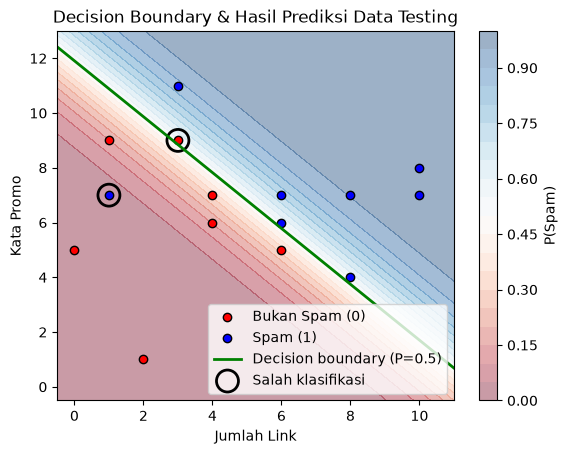

Data testing (yang salah diklasifikasikan diberi tanda):


,JumlahLink,KataPromo,Label Asli,Prediksi,P(Spam),Salah?
0,3,11,1,1,0.8806,benar
1,6,6,1,1,0.5496,benar
2,6,7,1,1,0.7553,benar
3,6,5,0,0,0.3255,benar
4,8,7,1,1,0.9535,benar
5,1,9,0,0,0.1480,benar
6,10,8,1,1,0.9971,benar
7,0,5,0,0,0.0016,benar
8,8,4,1,1,0.5589,benar
9,4,7,0,0,0.3172,benar


In [15]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f'Decision boundary: {m1:.4f}*x1 + {m2:.4f}*x2 + {b:.4f} = 0')
print(f'             atau: x2 = {(-b / m2):.4f} + {(-m1 / m2):.4f}*x1')

# 2. Visualisasi data testing + background probabilitas + decision boundary
x1, x2 = np.meshgrid(np.linspace(-0.5, 11, 250), np.linspace(-0.5, 13, 250))
grid = np.c_[x1.ravel(), x2.ravel()]
proba = classifier.predict_proba(grid).reshape(x1.shape)

x1_line = np.linspace(-0.5, 11, 100)
x2_line = -(b + m1 * x1_line) / m2

plt.contourf(x1, x2, proba, levels=20, cmap='RdBu', alpha=0.4)
plt.colorbar(label='P(Spam)')
plt.scatter(X_test2[y_test2 == 0, 0], X_test2[y_test2 == 0, 1], c='red', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(X_test2[y_test2 == 1, 0], X_test2[y_test2 == 1, 1], c='blue', edgecolors='k', label='Spam (1)')
plt.plot(x1_line, x2_line, c='g', lw=2, label='Decision boundary (P=0.5)')

# 3. Tandai data testing yang salah diklasifikasikan (prediksi != label asli)
salah = (y_pred2 != y_test2)
plt.scatter(X_test2[salah, 0], X_test2[salah, 1], s=250, facecolors='none',
            edgecolors='black', linewidths=2, label='Salah klasifikasi')
plt.title('Decision Boundary & Hasil Prediksi Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='lower right')
plt.show()

# daftar titik yang salah
email_tes = pd.DataFrame(X_test2, columns=['JumlahLink', 'KataPromo'])
email_tes['Label Asli'] = y_test2
email_tes['Prediksi'] = y_pred2
email_tes['P(Spam)'] = classifier.predict_proba(X_test2).round(4)
email_tes['Salah?'] = np.where(salah, 'SALAH', 'benar')
print('Data testing (yang salah diklasifikasikan diberi tanda):')
email_tes

**Jawaban B4 (analisis):**

Dari $b + m_1 x_1 + m_2 x_2 = 0$ didapat:

$$x_2 = \frac{11,05 - 0,947 x_1}{0,928} \approx 11,91 - 1,02 x_1$$

Di grafik, garis hijau itu boundary-nya. Area kanan atas (link banyak, kata promo banyak) daerah spam, area kiri bawah bukan spam.

Data testing yang salah ada 2 titik, saya kasih cincin hitam di grafik. Satu email spam yang posisinya dekat garis (probabilitasnya baru sedikit di bawah 0,5) jadi ketebak bukan spam, ini FN-nya. Satu lagi email bukan spam yang kebetulan fiturnya mirip spam (link atau kata promonya banyak), jadi ketebak spam, ini FP-nya. Jumlahnya cocok dengan confusion matrix di B3 (FP = 1, FN = 1).

Ini wajar terjadi karena kedua kelompok di datanya tidak terpisah rapi sama garis lurus. Ada email bukan spam yang kebetulan banyak linknya, jadi model yang cuma lihat 2 fitur ini (tanpa baca isi email) memang bisa keliru.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [16]:
# Jawaban B5
# 1. Prediksi dengan threshold 0.3, 0.5, dan 0.7
y_proba2 = classifier.predict_proba(X_test2)

# 2. Untuk setiap threshold: confusion matrix, precision, recall -> satu tabel
rows = []
for t in [0.3, 0.5, 0.7]:
    y_pred_t = classifier.predict(X_test2, threshold=t)
    tn, fp, fn, tp = confusion_matrix(y_test2, y_pred_t).ravel()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append({'Threshold': t, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'Precision': round(p, 4), 'Recall': round(r, 4),
                 'Accuracy': round(accuracy_score(y_test2, y_pred_t), 4)})

tabel_threshold = pd.DataFrame(rows)
tabel_threshold

,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,4,3,1,7,0.700,0.875,0.7333
1,0.5,6,1,1,7,0.875,0.875,0.8667
2,0.7,7,0,3,5,1.000,0.625,0.8000


**Jawaban B5 (analisis):**

| Threshold | TN, FP, FN, TP | Precision | Recall |
|---|---|---|---|
| 0.3 | 4, 3, 1, 7 | 0,700 | 0,875 |
| 0.5 | 6, 1, 1, 7 | 0,875 | 0,875 |
| 0.7 | 7, 0, 3, 5 | 1,000 | 0,625 |

Naik-turun threshold ngaruhnya ke timbangan antara precision dan recall. Threshold diturunkan (0.3) jadi email gampang banget dianggap spam: recall naik tapi FP ikut nambah (dari 1 jadi 3), precision anjlok ke 0,70. Sebaliknya threshold naik ke 0.7 model jadi picky: FP-nya malah jadi 0 (precision 1,0) tapi 3 dari 8 spam lolos, recall jatuh ke 0,625.

Pilihan saya tetap 0.5. Alasannya dari B3 saya bilang FP lebih bahaya, jadi logikanya mending pilih threshold tinggi biar precision aman. Tapi waktu lihat angkanya, threshold 0.7 kejatan banget, recall-nya roboh jadi 0,625, 3 email spam lolos masuk inbox. Sementara 0.5 dapat precision dan recall sama-sama 0,875, jadi keseimbangannya paling enak. 0.3 juga menarik sih untuk menangkap spam sebanyak mungkin, tapi FP-nya 3, kebanyakan buat selera saya.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [17]:
# Jawaban B6
# Prediksi kelas & probabilitas spam untuk 4 email baru
# (threshold yang dipilih dari analisis Soal B5 = 0.5, sama dengan default)
THRESHOLD = 0.5   # sesuai pilihan di jawaban B5

email_baru = pd.DataFrame({
    'Email':    ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo':  [2, 6, 10, 11],
})

X_baru = email_baru[['JumlahLink', 'KataPromo']].values
email_baru['P(Spam)'] = classifier.predict_proba(X_baru).round(4)
email_baru['Prediksi'] = classifier.predict(X_baru, threshold=THRESHOLD)
email_baru['Keterangan'] = np.where(email_baru['Prediksi'] == 1, 'Spam', 'Bukan Spam')
email_baru

,Email,JumlahLink,KataPromo,P(Spam),Prediksi,Keterangan
0,E1,1,2,0.0003,0,Bukan Spam
1,E2,5,6,0.3213,0,Bukan Spam
2,E3,9,10,0.9988,1,Spam
3,E4,2,11,0.7411,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Namanya masih ada "regression" karena di balik layar memang ada proses regresi: model menghitung $z = b + m_1x_1 + m_2x_2$ yang angkanya bebas (bisa -5, bisa 30, apapun). Yang bikin dia jadi klasifikasi adalah fungsi sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$ yang nerima angka berapa pun lalu memetakan ke rentang 0-1. Angka di rentang 0-1 ini kita baca sebagai probabilitas kelas 1. Terakhir tinggal diputuskan pakai threshold: kalau $P \geq$ 0,5 prediksi kelas 1, kalau nggak, kelas 0. Jadi sigmoidnya tugasnya "mentranslasi" output regresi jadi probabilitas, karena hasil akhirnya label kelas, dia termasuk klasifikasi.

**Jawaban C2:**

Normal equation langsung menghitung jawaban optimumnya sekali jalan lewat $\beta = (X^TX)^{-1}X^Ty$. Nggak ada learning rate, nggak ada iterasi, hasilnya pasti sama. Gradient descent mulai dari nol lalu melangkah pelan-pelan ke arah yang menurunkan MSE sampai konvergen, jadi hasilnya tergantung learning rate dan jumlah iterasi, seperti keliatan di eksperimen A5 tadi.

Normal equation enak untuk data kecil sampai menengah karena sekali hitung langsung selesai. Gradient descent lebih cocok kalau datanya gede banget (fitur banyak bikin invers matriks jadi mahal, kadang matriksnya bahkan nggak bisa diinvers) atau datanya terus nambah. Tapi harganya, learning rate-nya harus dipilih hati-hati, salah pilih bisa lambat atau divergen.

**Jawaban C3:**

Karena data training sudah pernah dilihat model waktu belajar. Kalau dievaluasi di situ, nilai bagusnya bisa cuma karena model hafal data latihnya, bukan karena dia paham polanya. Data testing belum pernah dilihat, jadi nilainya lebih jujur buat ngukur kemampuan model menghadapi data baru. Overfitting itu kejadian pas model belajar terlalu detail sampai ikut menghafal noise di data training, cirinya nilai di training bagus banget tapi di testing jauh lebih jelek. Makanya di A4 tadi saya bandingkan keduanya, selisih kecil antara train dan test artinya modelnya sehat.

**Jawaban C4:**

Output Linear Regression angka kontinu tanpa batas (bisa 50, bisa 137,55, bisa minus), dan MSE nyambung dengan itu karena loss-nya juga angka bebas. Logistic Regression outputnya probabilitas 0 sampai 1. Kalau MSE dipaksakan ke output sigmoid, kurva lossnya jadi berlekuk (non-convex), jadi ada banyak titik minimum palsu, dan gradientnya bisa jadi sangat kecil waktu sigmoid jenuh sehingga belajarnya lemot. Log loss datang dari maximum likelihood untuk label biner, kurvanya convex, dan dia ngasih hukuman gede ke prediksi yang yakin tapi salah, misalnya model bilang P(spam) = 0,999 ternyata emailnya bukan spam. Jadi pilihan loss ngikutin jenis output-nya: kontinu pakai MSE, probabilitas pakai log loss.

**Jawaban C5:**

Yang paling utama, random_state-nya beda. Instruksi tugas suruh pakai 2 digit terakhir NIM, jadi tiap mahasiswa split data train/test dengan urutan acak yang beda. Data train yang beda otomatis bikin koefisien yang dipelajari beda, dan angka evaluasinya ikut beda. Selain itu bisa karena beda versi library atau beda kecil di cara implementasi. Dataset dan algoritmanya sama, tapi "porsi" data yang dilihat tiap model beda, jadi hasil angkanya nggak mungkin persis sama antar mahasiswa.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [18]:
# Jawaban Bonus
# scikit-learn HANYA dipakai di sini (bonus), untuk membandingkan dengan implementasi sendiri
from sklearn.linear_model import LinearRegression as SkLearnLR
from sklearn.linear_model import LogisticRegression as SkLearnLogReg

print('=' * 70)
print('BAGIAN A: Linear Regression')
print('=' * 70)
sk_reg = SkLearnLR()
sk_reg.fit(X_train, y_train)
y_pred_sk = sk_reg.predict(X_test)

print('Implementasi sendiri : b = %.6f, m = %.6f' % (regressor.intercept_, regressor.coefficients_[0]))
print('sklearn              : b = %.4f, m = %.4f' % (sk_reg.intercept_, sk_reg.coef_[0]))
print()
print('Metrik testing -> implementasi sendiri vs sklearn:')
print('  R2  : %.6f vs %.6f' % (r2_score(y_test, regressor.predict(X_test)),
                                 r2_score(y_test, sk_reg.predict(X_test))))
print('  RMSE: %.4f vs %.4f' % (root_mean_squared_error(y_test, regressor.predict(X_test)),
                               root_mean_squared_error(y_test, sk_reg.predict(X_test))))

print()
print('=' * 70)
print('BAGIAN B: Logistic Regression')
print('=' * 70)
sk_clf = SkLearnLogReg(max_iter=10000)                     # default: regularisasi L2, C=1.0
sk_clf_noreg = SkLearnLogReg(C=np.inf, max_iter=10000)     # tanpa regularisasi (C tak hingga)

sk_clf.fit(X_train2, y_train2)
sk_clf_noreg.fit(X_train2, y_train2)

perbandingan = pd.DataFrame({
    'Model': ['Implementasi sendiri (GD, tanpa reg.)',
              'sklearn default (L2, C=1.0)',
              'sklearn tanpa regularisasi (C=np.inf)'],
    'Intercept': [classifier.intercept_, sk_clf.intercept_[0], sk_clf_noreg.intercept_[0]],
    'm1 (JumlahLink)': [classifier.coefficients_[0], sk_clf.coef_[0][0], sk_clf_noreg.coef_[0][0]],
    'm2 (KataPromo)': [classifier.coefficients_[1], sk_clf.coef_[0][1], sk_clf_noreg.coef_[0][1]],
    'Accuracy (test)': [accuracy_score(y_test2, y_pred2),
                        accuracy_score(y_test2, sk_clf.predict(X_test2)),
                        accuracy_score(y_test2, sk_clf_noreg.predict(X_test2))],
}).round(4)
display(perbandingan)

print()
print('Prediksi testing implementasi sendiri vs sklearn default sama persis:',
      np.array_equal(y_pred2, sk_clf.predict(X_test2)))

BAGIAN A: Linear Regression
Implementasi sendiri : b = 29.437523, m = 9.009131
sklearn              : b = 29.4375, m = 9.0091

Metrik testing -> implementasi sendiri vs sklearn:
  R2  : 0.922424 vs 0.922424
  RMSE: 8.1991 vs 8.1991

BAGIAN B: Logistic Regression


,Model,Intercept,m1 (JumlahLink),m2 (KataPromo),Accuracy (test)
0,"Implementasi sendiri (GD, tanpa reg.)",-11.0478,0.9466,0.9278,0.8667
1,"sklearn default (L2, C=1.0)",-10.2558,0.8670,0.8636,0.8667
2,sklearn tanpa regularisasi (C=np.inf),-12.1996,1.0545,1.0179,0.8667



Prediksi testing implementasi sendiri vs sklearn default sama persis: True


**Jawaban Bonus (analisis):**

Linear Regression: hasil sklearn sama persis dengan implementasi saya, $b = 29,4375$ dan $m = 9,0091$, metriknya juga identik. Ini masuk akal karena keduanya nyari solusi least squares yang sama, cuma caranya beda (sklearn pakai metode matriks yang lebih stabil, saya pakai invers langsung).

Logistic Regression: hasilnya beda, dan menurut saya ada 2 sebabnya.

Pertama, regularisasi. Kalau dibaca dokumentasinya, LogisticRegression sklearn default-nya pakai regularisasi L2 dengan $C = 1.0$. Regularisasi ini sengaja memperkecil koefisien biar model tidak terlalu ekstrem. Terlihat di tabel, koefisien sklearn default lebih kecil dari implementasi saya yang tanpa regularisasi.

Kedua, optimasinya beda. GD saya berhenti persis di 10.000 iterasi, dan loss-nya masih 0,214, belum konvergen bener-bener. sklearn pakai solver LBFGS yang jalan sampai konvergen. Waktu regularisasi sklearn saya matikan ($C = \infty$), koefisiennya malah lebih gede dari punya saya ($b=-12,20$ vs $b=-11,05$), ini nunjukin GD saya berhenti sebelum benar-benar konvergen, walaupun arah hasilnya udah bener.

Yang bikin saya dapat pelajaran: koefisien beda tapi prediksi testing sama (akurasi 86,67% di keduanya), jadi keputusan klasifikasinya nggak terlalu sensitif sama beda kecil koefisien. NumPy punya saya bagus buat ngerti proses di balik layar, sklearn lebih praktis untuk kerja beneran.